## Sentiment Classifier using Feedforward Neural Networks

In [ ]:
# ! pip install optuna
# ! pip install ftfy
# ! pip install --upgrade spacy
# ! python -m spacy download en_core_web_sm 
# ! pip install gensim

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import collections
import optuna
import html
import ftfy
import spacy
import os

from nltk import tokenize
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from gensim.models import Word2Vec
from sklearn.model_selection import learning_curve, train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_score,cross_validate
from optuna.samplers import TPESampler

nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

True

In [ ]:
import random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

RANDOM_SEED = 42
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

def set_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if hasattr(torch, "mps"):
        torch.mps.manual_seed(seed)

#### Loading the data:

In [ ]:
dataset_path = "../"

def load_dataset(file_path, train_path, val_path):
    train_df = pd.read_csv(file_path + train_path)
    val_df   = pd.read_csv(file_path + val_path)
    return train_df, val_df


def train_val_test_split(train_df, val_df, test_size=14000, random_state=RANDOM_SEED):

    positive_class = val_df[val_df["Label"] == 1].sample(n=test_size // 2, random_state=random_state)
    negative_class = val_df[val_df["Label"] == 0].sample(n=test_size // 2, random_state=random_state)

    test_df = pd.concat([positive_class, negative_class]).sample(n=test_size, random_state=random_state).reset_index(drop=True)
    val_df  = val_df.drop(positive_class.index.union(negative_class.index)).reset_index(drop=True)

    return train_df, val_df, test_df


In [ ]:
train_df, val_df = load_dataset(dataset_path, "train_dataset.csv", "val_dataset.csv")
train_df, val_df, test_df = train_val_test_split(train_df, val_df)
train_df = pd.concat([train_df, val_df]).reset_index(drop=True)

#### Text Preprocessing:

In [ ]:
def replace_emoticons(text):
    text = re.sub(r"</3", " heartbroken ", text)
    text = re.sub(r"<3",  " love ", text)
    text = re.sub(r":'\(", " crying ", text)
    text = re.sub(r":d",  " laugh ", text)
    text = re.sub(r":-d", " laugh ", text)
    text = re.sub(r"=d",  " laugh ", text)
    text = re.sub(r"xd",  " laugh ", text)
    text = re.sub(r"d:",  " laugh ", text)
    text = re.sub(r";\)",  " wink ", text)
    text = re.sub(r";-\)", " wink ", text)
    text = re.sub(r";d",   " wink ", text)
    text = re.sub(r":p",   " playful ", text)
    text = re.sub(r":-p",  " playful ", text)
    text = re.sub(r"=p",   " playful ", text)
    text = re.sub(r";p",   " playful ", text)
    text = re.sub(r"xp",   " playful ", text)
    text = re.sub(r":/",   " confused ", text)
    text = re.sub(r":-/",  " confused ", text)
    text = re.sub(r"=/",   " confused ", text)
    text = re.sub(r":\\",  " confused ", text)
    text = re.sub(r":o",   " surprised ", text)
    text = re.sub(r":-o",  " surprised ", text)
    text = re.sub(r":\(",  " sad ", text)
    text = re.sub(r":-\(", " sad ", text)
    text = re.sub(r"=\(",  " sad ", text)
    text = re.sub(r"\):",  " sad ", text)
    text = re.sub(r";\(",  " sad ", text)
    text = re.sub(r":\)",  " smile ", text)
    text = re.sub(r":-\)", " smile ", text)
    text = re.sub(r"=\)",  " smile ", text)
    text = re.sub(r"\(:",  " smile ", text)
    text = re.sub(r":\*",  " kiss ", text)
    text = re.sub(r":-\*", " kiss ", text)
    return text

abbreviations = {
    "lol": "laugh", "lmao": "laugh", "lmfao": "laugh", "rofl": "laugh",

    "omg": "oh my god",
    "wtf": "what the fuck",
    "wth": "what the hell",
    "fml": "fuck my life",
    "smh": "shake my head",

    "btw": "by the way",
    "idk": "i do not know",
    "ily": "i love you",
    "tbh": "to be honest",
    "imo": "in my opinion",
    "imho": "in my humble opinion",
    "asap": "as soon as possible",
    "fyi": "for your information",
    "jk": "just kidding",
    "ttyl": "talk to you later",
    "atm": "at the moment",
    "brb": "be right back",
    "dm": "direct message",

    "thx": "thanks", "thnx": "thanks",
    "ty": "thank you",
    "pls": "please", "plz": "please",

    "tmrw": "tomorrow", "tmr": "tomorrow",
    "2moro": "tomorrow", "2morrow": "tomorrow",
    "2day": "today",
    "2nite": "tonight", "2night": "tonight", "tonite": "tonight",

    "1st": "first", "2nd": "second", "3rd": "third",
    "b4": "before",
}

slang = {

    "luv": "love",
    "cuz": "because", "coz": "because", "bcuz": "because",
    "wit": "with",
    "wat": "what",
    "kno": "know",
    "hav": "have",
    "ya": "you",
    "lil": "little",
    "u": "you",
    "ur": "your",
    "r": "are",

    "yea": "yes", "yup": "yes",
    "nope": "no", "nah": "no",

    "goin": "going", "doin": "doing", "havin": "having",
    "lovin": "loving", "hatin": "hating", "tryin": "trying",
    "seein": "seeing", "sayin": "saying", "eatin": "eating",
    "playin": "playing", "livin": "living", "workin": "working",
    "runnin": "running", "movin": "moving", "missin": "missing",
    "killin": "killing", "freakin": "freaking", "comin": "coming",

    "bro": "brother",
    "sis": "sister",
    "fam": "family",
    "bday": "birthday",
    "pic": "picture", "pics": "pictures",
    "fav": "favorite",
    "vid": "video",
    "prob": "probably", "probs": "probably"
}

contractions = {
   
    "i'm": "i am", "it's": "it is", "he's": "he is", "she's": "she is",
    "we're": "we are", "you're": "you are", "they're": "they are",
    "that's": "that is", "what's": "what is", "where's": "where is",
    "there's": "there is", "here's": "here is", "who's": "who is",
    "how's": "how is",

    "i've": "i have", "you've": "you have", "we've": "we have",
    "they've": "they have",

    "i'll": "i will", "you'll": "you will", "he'll": "he will",
    "she'll": "she will", "we'll": "we will", "they'll": "they will",
    "it'll": "it will",

    "i'd": "i would", "you'd": "you would", "he'd": "he would",
    "she'd": "she would", "we'd": "we would", "they'd": "they would",

    "don't": "do not", "doesn't": "does not", "didn't": "did not",
    "can't": "can not", "won't": "will not", "wouldn't": "would not",
    "shouldn't": "should not", "couldn't": "could not", "mustn't": "must not",
    "isn't": "is not", "aren't": "are not", "wasn't": "was not",
    "weren't": "were not", "hasn't": "has not", "haven't": "have not",
    "hadn't": "had not",

    "let's": "let us",

    "im": "i am", "hes": "he is", "shes": "she is",
    "youre": "you are", "theyre": "they are",
    "thats": "that is", "whats": "what is", "wheres": "where is",
    "theres": "there is", "heres": "here is",

    "ive": "i have", "youve": "you have",

    "dont": "do not", "doesnt": "does not", "didnt": "did not",
    "cant": "can not", "wont": "will not", "wouldnt": "would not",
    "shouldnt": "should not", "couldnt": "could not",
    "isnt": "is not", "wasnt": "was not",
    "havent": "have not", "hasnt": "has not",
    "wanna": "want to", "gonna": "going to",
    "gotta": "got to", "dunno": "do not know",
    "kinda": "kind of", "sorta": "sort of",
    "outta": "out of", "lemme": "let me",
    "gimme": "give me", "yall": "you all"
}


In [ ]:
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

def apply_lemmatization(text):
    return " ".join(token.lemma_ for token in nlp(text))

In [ ]:
def remove_mentions(text):
    return re.sub(r"@\w+", "", text)

def remove_urls(text):
    return re.sub(r"http\S+|www\S+|https\S+", " ", text)

def remove_digits(text):
    return re.sub(r"\d+", "", text)

def remove_alphanumeric(text):
    return re.sub(r"\w*\d\w*", "", text)

def remove_short_words(text):
    return " ".join(w for w in text.split() if len(w) > 1)

def remove_punctuation(text):
    return re.sub(r"[^\w\s]", " ", text)

def remove_extra_spaces(text):
    return re.sub(r"\s+", " ", text).strip()

def convert_to_lowercase(text):
    return text.lower()

def remove_repeated_chars(text):
    return re.sub(r"(.)\1{2,}", r"\1", text)

def remove_stopwords(text):
    stop_words = set(stopwords.words('english'))
    return " ".join([word for word in text.split() if word not in stop_words])

def fix_mojibake(text):
    return ftfy.fix_text(text)

def replace_abbreviations(text):
    return " ".join([abbreviations.get(word, word) for word in text.split()])

def replace_slang(text):
    return " ".join([slang.get(word, word) for word in text.split()])

def replace_contractions(text):
    return " ".join([contractions.get(word, word) for word in text.split()])


def clean_text(text):

    text = fix_mojibake(text)               # encodes characters correctly
    text = convert_to_lowercase(text)
    text = html.unescape(text)          #recovers html entities
    text = remove_mentions(text)
    text = remove_urls(text)
    text = replace_emoticons(text)

    text = replace_abbreviations(text)
    text = replace_slang(text)
    text = replace_contractions(text)

    text = remove_digits(text)
    text = remove_punctuation(text)
    
    text = remove_alphanumeric(text)
    text = remove_short_words(text)
    text = remove_repeated_chars(text)
    text = apply_lemmatization(text)         
    text = remove_extra_spaces(text)

    return text

In [ ]:
train_df["Text"].head(20)

0         @whoisralphie dude  I'm so bummed ur leaving!
1     oh my god, a severed foot was foun in a wheely...
2     I end up &quot;dog dialing&quot; sumtimes. Wha...
3                            @_rachelx meeeee toooooo! 
4     I was hoping I could stay home and work today,...
5     says plurk karma finally reached the 50s. stil...
6     Good to hear it @Arth This is a bit more, but ...
7     @davorg in that case im gonna start tweeting a...
8             @belunyc its alright love, how are you?  
9     @brightondoll haha that has to be the best ana...
10    @AlpacaFarmgirl Biscuit is our cat. We've had ...
11    @1capplegate I'm so sad about Sam Who  it was ...
12    trying to stay healthy. 2 of 4 of this Devine ...
13    My bro stole my big bag, my pink bag is gone. ...
14                 my hair wont go right! sighsighsigh 
15       I got bored so I slept, now I'm a little sad. 
16    @LunaBellaMUA   I'm probably being blonde...bu...
17    @janinaz love this game on PS3 too ^^ i th

In [ ]:
train_df["Text"] = train_df["Text"].apply(clean_text)
val_df["Text"]   = val_df["Text"].apply(clean_text)
test_df["Text"]  = test_df["Text"].apply(clean_text)

In [ ]:
train_df["Text"].head(20)

0                        dude be so bummed your leaving
1     oh my god sever foot be foun in wheely bin in ...
2     end up dog dial sumtime what be dog dialing yo...
3                                                  I to
4     be hop could stay home and work today but look...
5     say plurk karma finally reach the still no hea...
6     good to hear it this be bit more but la four t...
7     in that case be go to start tweet about nympho...
8                           its alright love how be you
9     haha that have to be the good analogy ever mog...
10    biscuit be our cat we have have he for year an...
11    be so sad about sam who it be my favorite sitc...
12    try to stay healthy of of this devine family f...
13    my brother steal my big bag my pink bag be go ...
14               my hair will not go right sighsighsigh
15                  get bore so sleep now be little sad
16        be probably be blonde but my reaction to what
17    love this game on ps too think it be my fa

#### Training Word2Vec model:

In [ ]:
if os.path.exists("word2vec_model.model"):
    w2v_model = Word2Vec.load("word2vec_model.model")
else:
    list_of_tokenized_tweets = [word_tokenize(tweet) for tweet in train_df["Text"]]

    # using default parameters for Word2Vec
    w2v_model = Word2Vec(sentences=list_of_tokenized_tweets, vector_size=300, workers=1, sg=1, seed=RANDOM_SEED)
    w2v_model.save("word2vec_model.model")


Creating sentence embeddings from word embeddings: 

In [ ]:
def average_word_embeddings(tokens, model, embedding_dim):     #mean pooling
    token_to_index = model.wv.key_to_index
    indices = [token_to_index[token] for token in tokens if token in token_to_index]
    if not indices:
        return np.zeros(embedding_dim, dtype=np.float32)
    return model.wv.vectors[indices].mean(axis=0)

In [ ]:
emb_dim = w2v_model.vector_size 
x_train = []
x_test = []          

for tweet in train_df["Text"]:
    tokens = word_tokenize(tweet)
    sentence_embedding = average_word_embeddings(tokens, w2v_model, emb_dim)
    x_train.append(sentence_embedding)

for tweet in test_df["Text"]:
    tokens = word_tokenize(tweet)
    sentence_embedding = average_word_embeddings(tokens, w2v_model, emb_dim)
    x_test.append(sentence_embedding)

In [ ]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print(f"Running on: {device}")

Running on: mps


In [ ]:
x_train = np.array(x_train, dtype=np.float32)
y_train = np.array(train_df["Label"], dtype=np.float32)

x_test = np.array(x_test, dtype=np.float32)
y_test = np.array(test_df["Label"], dtype=np.float32)

In [ ]:
x_train = torch.tensor(x_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)

x_test = torch.tensor(x_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=RANDOM_SEED)

print(x_train.shape, y_train.shape)
print(x_val.shape, y_val.shape)

torch.Size([141427, 300]) torch.Size([141427, 1])
torch.Size([35357, 300]) torch.Size([35357, 1])


#### Feedforward neural network with two hidden layers:

In [ ]:
class FeedforwardNN_2(nn.Module):
    def __init__(self, embedding_dim, h1_d, h2_d, output_dim, activation_funct, dropout_prob):
        super().__init__()
        self.linear1 = nn.Linear(embedding_dim, h1_d)
        self.linear2 = nn.Linear(h1_d, h2_d)
        self.linear3 = nn.Linear(h2_d, output_dim)
        self.act_fn = activation_funct
        self.dropout = nn.Dropout(dropout_prob)

    def forward(self, x):
        x = self.linear1(x)
        x = self.act_fn(x)
        x = self.dropout(x)

        x = self.linear2(x)
        x = self.act_fn(x)
        x = self.dropout(x)

        x = self.linear3(x)
        return x

#### Feedforward neural network with three hidden layers:

In [ ]:
class FeedforwardNN_3(nn.Module):
    def __init__(self, embedding_dim, h1_d, h2_d, h3_d, output_dim, activation_funct, dropout_prob):
        super().__init__()
        self.linear1 = nn.Linear(embedding_dim, h1_d)
        self.linear2 = nn.Linear(h1_d, h2_d)
        self.linear3 = nn.Linear(h2_d, h3_d)
        self.linear4 = nn.Linear(h3_d, output_dim)
        self.act_fn = activation_funct
        self.dropout = nn.Dropout(dropout_prob)

    def forward(self, x):
        x = self.linear1(x)
        x = self.act_fn(x)
        x = self.dropout(x)

        x = self.linear2(x)
        x = self.act_fn(x)
        x = self.dropout(x)

        x = self.linear3(x)
        x = self.act_fn(x)
        x = self.dropout(x)

        x = self.linear4(x)
        return x

In [ ]:
train_dataset = TensorDataset(x_train, y_train)
val_dataset = TensorDataset(x_val, y_val)

In [ ]:
def evaluate(model, test_dataloader, loss_fn, device):

    model.eval()

    test_loss = 0
    y_predictions = []
    y_labels = []
    num_of_batches = len(test_dataloader)

    with torch.no_grad():
        for x_test_batch, y_test_batch in test_dataloader:

            x_test_batch = x_test_batch.to(device)
            y_test_batch = y_test_batch.to(device)

            y_logits = model(x_test_batch)
            test_loss += loss_fn(y_logits, y_test_batch).item()

            sigmoid_values = torch.sigmoid(y_logits)           #probabilites from the sigmoid function
            y_preds = torch.round(sigmoid_values)

            y_predictions.append(y_preds.cpu())
            y_labels.append(y_test_batch.cpu())

    avg_test_loss = test_loss / num_of_batches              #average test loss over all batches

    y = torch.cat(y_labels).squeeze().numpy()
    y_pred = torch.cat(y_predictions).squeeze().numpy()

    accuracy  = accuracy_score(y, y_pred)
    precision = precision_score(y, y_pred)
    recall = recall_score(y, y_pred)
    f1 = f1_score(y, y_pred)

    return avg_test_loss, accuracy, precision, recall, f1, y, y_pred


In [ ]:
def train(model, train_dataloader, test_dataloader, loss_fn, optimizer, num_of_epochs, device, early_stopping=True, 
          patience=7,train_losses=None, test_losses=None, train_acc=None, test_acc=None, train_f1=None, test_f1=None, 
          verbose=True):


    if verbose:
        print(f"Training started!")
        print()

    best_val_loss = float('inf')
    patience_counter = 0

    for epoch in range(num_of_epochs):

        model.train()

        loss_per_epoch = 0
        num_of_batches = len(train_dataloader)

        y_train_predictions = []
        y_train_labels = []

        for x_batch, y_batch in train_dataloader:

            x_batch, y_batch = x_batch.to(device), y_batch.to(device) 

            y_preds = model(x_batch)
            loss = loss_fn(y_preds, y_batch)
            loss_per_epoch += loss.item()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            with torch.no_grad():            #store predictions on the training set 
                sigmoid_values = torch.sigmoid(y_preds)           
                y_predictions = torch.round(sigmoid_values)

                y_train_predictions.append(y_predictions.cpu())
                y_train_labels.append(y_batch.cpu())

        avg_train_loss = loss_per_epoch / num_of_batches         #average train loss per epoch
        y = torch.cat(y_train_labels).squeeze().numpy()     
        y_pred = torch.cat(y_train_predictions).squeeze().numpy()     #predictions on the training set
        train_accuracy = accuracy_score(y, y_pred)
        train_f1_score = f1_score(y, y_pred)

        
        # evaluate the model on the validation set on every epoch 
        avg_val_loss, accuracy, precision, recall, f1, _, _ = evaluate(model, test_dataloader, loss_fn, device)
        

        if train_losses is not None:                       
            train_losses.append(avg_train_loss)
        if test_losses is not None:
            test_losses.append(avg_val_loss)
        if train_acc is not None:
            train_acc.append(train_accuracy)
        if test_acc is not None:
            test_acc.append(accuracy)
        if train_f1 is not None:
            train_f1.append(train_f1_score)
        if test_f1 is not None:
            test_f1.append(f1)
        
        if early_stopping:                        #implements early stopping 
            if avg_val_loss < best_val_loss:   
                best_val_loss = avg_val_loss  
                patience_counter = 0
            else:                       
                patience_counter += 1 
                if patience_counter >= patience:
                    if verbose:
                        print(f"Epoch {epoch + 1}/{num_of_epochs} | Train Loss: {avg_train_loss:.4f} | Train Accuracy: {train_accuracy:.4f} | Train f1-score: {train_f1_score:.4f}")
                        print(f"Epoch {epoch + 1}/{num_of_epochs} | Validation Loss: {avg_val_loss:.4f} | Validation Accuracy: {accuracy:.4f} | Validation f1-score: {f1:.4f}")
                        print("Early stopping triggered!")
                    break
           
        
        if verbose:
            print(f"Epoch {epoch + 1}/{num_of_epochs} | Train Loss: {avg_train_loss:.4f} | Train Accuracy: {train_accuracy:.4f} | Train f1-score: {train_f1_score:.4f}")
            print(f"Epoch {epoch + 1}/{num_of_epochs} | Validation Loss: {avg_val_loss:.4f} | Validation Accuracy: {accuracy:.4f} | Validation f1-score: {f1:.4f}")
            print()

    return avg_train_loss, avg_val_loss, accuracy, precision, recall, f1
        



#### Hyperparameter tuning using optuna:

We run two studies to identify the optimal parameters for each fnn architecture. 

In [ ]:
def objective_network_two_hidden_layers(trial):
    set_seed(RANDOM_SEED)

    h1_d = trial.suggest_int("hidden_layer1_d", 64, 512, step=64)
    h2_d = trial.suggest_int("hidden_layer2_d", 64, h1_d, step=64)
    batch_size = trial.suggest_categorical("batch_size", [64, 128, 256])
    dropout = trial.suggest_float("dropout", 0.2, 0.5)
    learning_rate = trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True)

    epochs = 50

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    model = FeedforwardNN_2(emb_dim, h1_d, h2_d, 1, nn.ReLU(), dropout).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()

    _, _, accuracy, _, _, _ = train(model, train_loader, val_loader, loss_fn, optimizer, epochs, device, verbose=False)

    return accuracy

study_network_2layers = optuna.create_study(direction="maximize", sampler=TPESampler(seed=RANDOM_SEED))
study_network_2layers.optimize(objective_network_two_hidden_layers, n_trials=50)

best_val_2layers = study_network_2layers.best_value
best_params_2layers = study_network_2layers.best_params

print(f"Best Accuracy score: {study_network_2layers.best_value:.6f}")
print(f"Best params: {study_network_2layers.best_params}")

[I 2026-11-01 22:41:41,659] A new study created in memory with name: no-name-3fa2df6f-b59e-48ca-9ec4-ecad191ed2f7
[I 2026-11-01 22:44:38,474] Trial 0 finished with value: 0.781910229940323 and parameters: {'hidden_layer1_d': 192, 'hidden_layer2_d': 192, 'batch_size': 64, 'dropout': 0.24679835610086082, 'learning_rate': 0.00013066739238053285, 'weight_decay': 0.003967605077052989}. Best is trial 0 with value: 0.781910229940323.
[I 2026-11-01 22:46:12,142] Trial 1 finished with value: 0.7841162994597958 and parameters: {'hidden_layer1_d': 320, 'hidden_layer2_d': 256, 'batch_size': 128, 'dropout': 0.26370173320348284, 'learning_rate': 0.0002310201887845295, 'weight_decay': 3.5498788321965036e-05}. Best is trial 1 with value: 0.7841162994597958.
[I 2026-11-01 22:47:32,981] Trial 2 finished with value: 0.7840597335746811 and parameters: {'hidden_layer1_d': 192, 'hidden_layer2_d': 128, 'batch_size': 256, 'dropout': 0.24184815819561256, 'learning_rate': 0.0003839629299804173, 'weight_decay': 

Best Accuracy score: 0.787397
Best params: {'hidden_layer1_d': 384, 'hidden_layer2_d': 320, 'batch_size': 128, 'dropout': 0.47045460594214294, 'learning_rate': 0.00018841655863912764, 'weight_decay': 0.005563663931171337}


In [ ]:
def objective_network_three_hidden_layers(trial):
    set_seed(RANDOM_SEED)

    h1_d = trial.suggest_int("hidden_layer1_d", 64, 512, step=64)
    h2_d = trial.suggest_int("hidden_layer2_d", 64, h1_d, step=64)
    h3_d = trial.suggest_int("hidden_layer3_d", 64, h2_d, step=64)
    batch_size = trial.suggest_categorical("batch_size", [64, 128, 256])
    dropout = trial.suggest_float("dropout", 0.2, 0.5)
    learning_rate = trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True)

    epochs = 50

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    
    model = FeedforwardNN_3(emb_dim, h1_d, h2_d, h3_d, 1, nn.ReLU(), dropout).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()

    _, _, accuracy, _, _, _ = train(model, train_loader, val_loader, loss_fn, optimizer, epochs, device, verbose=False)

    return accuracy

study_network_3layers = optuna.create_study(direction="maximize", sampler=TPESampler(seed=RANDOM_SEED))
study_network_3layers.optimize(objective_network_three_hidden_layers, n_trials=50)

best_val_3layers = study_network_3layers.best_value
best_params_3layers = study_network_3layers.best_params

print(f"Best Accuracy score: {study_network_3layers.best_value:.6f}")
print(f"Best params: {study_network_3layers.best_params}")


[I 2026-11-02 00:41:39,952] A new study created in memory with name: no-name-fd29dc8c-003a-4404-ac62-457131b59a8e
[I 2026-11-02 00:44:47,077] Trial 0 finished with value: 0.7715021070792205 and parameters: {'hidden_layer1_d': 192, 'hidden_layer2_d': 192, 'hidden_layer3_d': 192, 'batch_size': 64, 'dropout': 0.21742508365045984, 'learning_rate': 0.005399484409787433, 'weight_decay': 0.0006358358856676254}. Best is trial 0 with value: 0.7715021070792205.
[I 2026-11-02 00:47:39,576] Trial 1 finished with value: 0.7825041717340272 and parameters: {'hidden_layer1_d': 384, 'hidden_layer2_d': 64, 'hidden_layer3_d': 64, 'batch_size': 64, 'dropout': 0.2545474901621302, 'learning_rate': 0.00023270677083837802, 'weight_decay': 8.17949947521167e-05}. Best is trial 1 with value: 0.7825041717340272.
[I 2026-11-02 00:50:12,348] Trial 2 finished with value: 0.7828718499872727 and parameters: {'hidden_layer1_d': 320, 'hidden_layer2_d': 192, 'hidden_layer3_d': 64, 'batch_size': 64, 'dropout': 0.309908552

Best Accuracy score: 0.788585
Best params: {'hidden_layer1_d': 320, 'hidden_layer2_d': 64, 'hidden_layer3_d': 64, 'batch_size': 256, 'dropout': 0.3595464687037234, 'learning_rate': 0.00010213291387456481, 'weight_decay': 0.0003503621407521286}


In [ ]:
if best_val_2layers > best_val_3layers:
    best_model_params = best_params_2layers
    best_model_val = best_val_2layers

    print(f"Best scores and parameters were found for the network with 2 hidden layers!")
    print(f"Best accuracy score for newtwork with 2 layers: {best_model_val:.6f}")
    print(f"Best params for network with 2 layers: {best_model_params}")
else:
    best_model_params = best_params_3layers
    best_model_val = best_val_3layers

    print(f"Best scores and parameters were found for the network with 3 hidden layers!")
    print(f"Best accuracy score for newtwork with 3 layers: {best_model_val:.6f}")
    print(f"Best params for network with 3 layers: {best_model_params}")

Best scores and parameters were found for the network with 3 hidden layers!
Best accuracy score for newtwork with 3 layers: 0.788585
Best params for network with 3 layers: {'hidden_layer1_d': 320, 'hidden_layer2_d': 64, 'hidden_layer3_d': 64, 'batch_size': 256, 'dropout': 0.3595464687037234, 'learning_rate': 0.00010213291387456481, 'weight_decay': 0.0003503621407521286}


#### Retraining both models (fnn with two hidden layers and fnn with three hidden layers) using hyperparameter values returned by optuna:

In [ ]:
# Feedforward Neural Network with two hidden layers
set_seed(RANDOM_SEED)
train_loader = DataLoader(train_dataset, batch_size=best_params_2layers["batch_size"], shuffle=True)
val_loader  = DataLoader(val_dataset,  batch_size=best_params_2layers["batch_size"], shuffle=False)

fnn_two_hidden_layers = FeedforwardNN_2(emb_dim, 
            best_params_2layers["hidden_layer1_d"], best_params_2layers["hidden_layer2_d"], 
            1, nn.ReLU(), best_params_2layers["dropout"]).to(device)

loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(fnn_two_hidden_layers.parameters(), 
            lr=best_params_2layers["learning_rate"], weight_decay=best_params_2layers["weight_decay"])

In [ ]:
train_losses, test_losses = [], []
train_accuracies, test_accuracies = [], []
train_f1_scores, test_f1_scores = [], []

_,_, accuracy, precision, recall, f1 = train(fnn_two_hidden_layers, train_loader, val_loader,
    loss_fn, optimizer, num_of_epochs=50, device=device, early_stopping=True, 
    train_losses=train_losses, test_losses=test_losses, train_acc=train_accuracies, 
    test_acc=test_accuracies, train_f1=train_f1_scores, test_f1=test_f1_scores, verbose=True)

Training started!

Epoch 1/50 | Train Loss: 0.5279 | Train Accuracy: 0.7355 | Train f1-score: 0.7263
Epoch 1/50 | Validation Loss: 0.5003 | Validation Accuracy: 0.7539 | Validation f1-score: 0.7340

Epoch 2/50 | Train Loss: 0.4957 | Train Accuracy: 0.7589 | Train f1-score: 0.7554
Epoch 2/50 | Validation Loss: 0.4852 | Validation Accuracy: 0.7635 | Validation f1-score: 0.7573

Epoch 3/50 | Train Loss: 0.4890 | Train Accuracy: 0.7636 | Train f1-score: 0.7607
Epoch 3/50 | Validation Loss: 0.4803 | Validation Accuracy: 0.7675 | Validation f1-score: 0.7624

Epoch 4/50 | Train Loss: 0.4844 | Train Accuracy: 0.7664 | Train f1-score: 0.7635
Epoch 4/50 | Validation Loss: 0.4770 | Validation Accuracy: 0.7694 | Validation f1-score: 0.7743

Epoch 5/50 | Train Loss: 0.4807 | Train Accuracy: 0.7690 | Train f1-score: 0.7664
Epoch 5/50 | Validation Loss: 0.4789 | Validation Accuracy: 0.7674 | Validation f1-score: 0.7498

Epoch 6/50 | Train Loss: 0.4779 | Train Accuracy: 0.7709 | Train f1-score: 0.7683

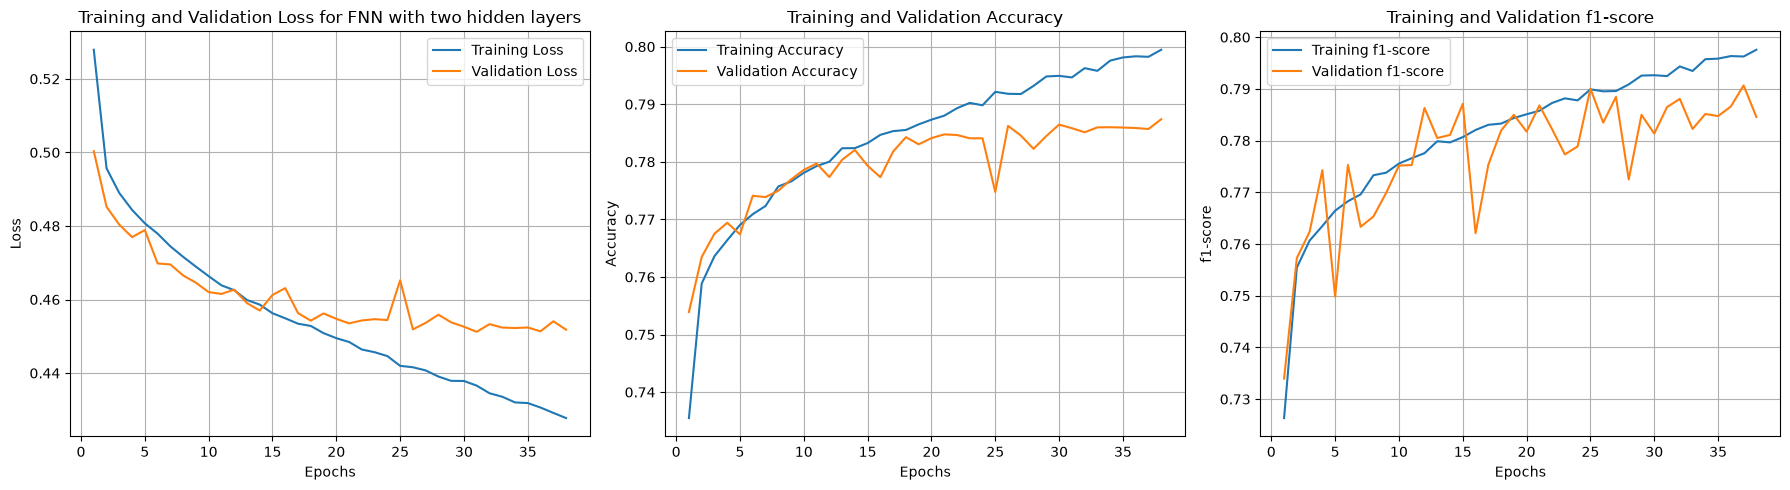

In [ ]:
def plot_train_val_curves(train_values, val_values, title, ylabel, ax):
    epochs = range(1, len(train_values) + 1)

    ax.plot(epochs, train_values, label=f"Training {ylabel}")
    ax.plot(epochs, val_values, label=f"Validation {ylabel}")
    ax.set_xlabel("Epochs")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(True)


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_train_val_curves(train_losses, test_losses, "Training and Validation Loss for FNN with two hidden layers", "Loss", axes[0])
plot_train_val_curves(train_accuracies, test_accuracies, "Training and Validation Accuracy", "Accuracy", axes[1])
plot_train_val_curves(train_f1_scores, test_f1_scores, "Training and Validation f1-score", "f1-score", axes[2])

plt.tight_layout()
plt.show()

We observe that all the above metrics are noisy, especially accuracy and f1-score. The validation loss decreases over the first epochs until it starts to plateau. Implementing early stopping prevents the model from overfitting.

In [ ]:
_, acc, prec, rec, f1, y_true, y_pred = evaluate(fnn_two_hidden_layers, val_loader, loss_fn, device)

print("Classification Report — FNN with two hidden layers:")
print(classification_report(y_true, y_pred, digits=4))

Classification Report — FNN with two hidden layers:
              precision    recall  f1-score   support

         0.0     0.7752    0.8056    0.7902     17566
         1.0     0.8004    0.7694    0.7846     17791

    accuracy                         0.7874     35357
   macro avg     0.7878    0.7875    0.7874     35357
weighted avg     0.7879    0.7874    0.7873     35357



In [ ]:
# Feedforward Neural Network with three hidden layers
set_seed(RANDOM_SEED)
train_loader = DataLoader(train_dataset, batch_size=best_params_3layers['batch_size'], shuffle=True)
val_loader  = DataLoader(val_dataset,  batch_size=best_params_3layers['batch_size'], shuffle=False)

fnn_three_hidden_layers = FeedforwardNN_3(emb_dim,
            best_params_3layers["hidden_layer1_d"], best_params_3layers["hidden_layer2_d"], 
            best_params_3layers["hidden_layer3_d"],1, nn.ReLU(), best_params_3layers["dropout"]).to(device)

loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(fnn_three_hidden_layers.parameters(),
            lr=best_params_3layers["learning_rate"], weight_decay=best_params_3layers["weight_decay"])

In [ ]:
train_losses, test_losses = [], []
train_accuracies, test_accuracies = [], []
train_f1_scores, test_f1_scores = [], []

_,_, accuracy, precision, recall, f1 = train(fnn_three_hidden_layers, train_loader, val_loader, loss_fn, optimizer,
    num_of_epochs=50, device=device, early_stopping=True, patience=7, train_losses=train_losses, 
    test_losses=test_losses, train_acc=train_accuracies, test_acc=test_accuracies, 
    train_f1=train_f1_scores, test_f1=test_f1_scores, verbose=True)

Training started!

Epoch 1/50 | Train Loss: 0.5897 | Train Accuracy: 0.6893 | Train f1-score: 0.7023
Epoch 1/50 | Validation Loss: 0.5097 | Validation Accuracy: 0.7510 | Validation f1-score: 0.7460

Epoch 2/50 | Train Loss: 0.5147 | Train Accuracy: 0.7517 | Train f1-score: 0.7483
Epoch 2/50 | Validation Loss: 0.5004 | Validation Accuracy: 0.7574 | Validation f1-score: 0.7615

Epoch 3/50 | Train Loss: 0.5059 | Train Accuracy: 0.7567 | Train f1-score: 0.7531
Epoch 3/50 | Validation Loss: 0.4943 | Validation Accuracy: 0.7595 | Validation f1-score: 0.7525

Epoch 4/50 | Train Loss: 0.5001 | Train Accuracy: 0.7597 | Train f1-score: 0.7563
Epoch 4/50 | Validation Loss: 0.4901 | Validation Accuracy: 0.7618 | Validation f1-score: 0.7573

Epoch 5/50 | Train Loss: 0.4965 | Train Accuracy: 0.7621 | Train f1-score: 0.7590
Epoch 5/50 | Validation Loss: 0.4883 | Validation Accuracy: 0.7628 | Validation f1-score: 0.7683

Epoch 6/50 | Train Loss: 0.4934 | Train Accuracy: 0.7641 | Train f1-score: 0.7614

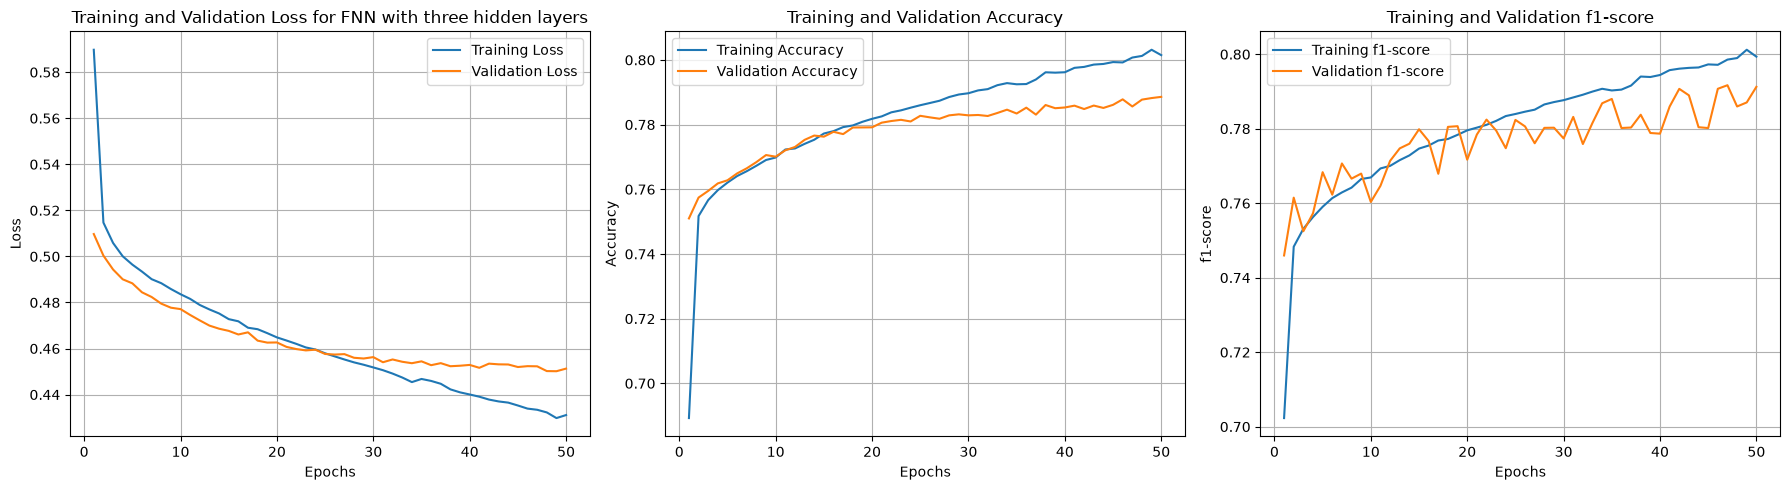

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_train_val_curves(train_losses, test_losses, "Training and Validation Loss for FNN with three hidden layers", "Loss", axes[0])
plot_train_val_curves(train_accuracies, test_accuracies, "Training and Validation Accuracy", "Accuracy", axes[1])
plot_train_val_curves(train_f1_scores, test_f1_scores, "Training and Validation f1-score", "f1-score", axes[2])
plt.tight_layout()
plt.show()

Compared to the previous results, the loss and the metrics of the 3-layer fnn are less noisy. Again the validation loss decreases and then smoothly plateaus. The gap between training and validation loss, as well as between training and validation accuracy is smaller in this case. This suggests that this model generalizes better. 

In [ ]:
_, acc, prec, rec, f1, y_true, y_pred = evaluate(fnn_three_hidden_layers, val_loader, loss_fn, device)

print("Classification Report — FNN with three hidden layers:")
print(classification_report(y_true, y_pred, digits=4))

Classification Report — FNN with three hidden layers:
              precision    recall  f1-score   support

         0.0     0.7910    0.7808    0.7858     17566
         1.0     0.7863    0.7963    0.7913     17791

    accuracy                         0.7886     35357
   macro avg     0.7886    0.7885    0.7886     35357
weighted avg     0.7886    0.7886    0.7886     35357



#### Evaluation on the test set:

Based on the above analysis we decide to use the 3-layer fnn for the evaluation on the test set.

In [ ]:
test_dataset = TensorDataset(x_test, y_test)
test_loader  = DataLoader(test_dataset, batch_size=256, shuffle=False)

loss_fn = nn.BCEWithLogitsLoss()
test_loss, accuracy, precision, recall, f1, y_true, y_pred = evaluate(
    fnn_three_hidden_layers, test_loader, loss_fn, device)

print("Metric score results on the test set:")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print()

print("Classification Report for the test set:")
print(classification_report(y_true, y_pred, digits=4))

Metric score results on the test set:
Accuracy:  0.7839
Precision: 0.7784
Recall:    0.7937
F1-score:  0.7860

Classification Report for the test set:
              precision    recall  f1-score   support

         0.0     0.7896    0.7740    0.7817      7000
         1.0     0.7784    0.7937    0.7860      7000

    accuracy                         0.7839     14000
   macro avg     0.7840    0.7839    0.7838     14000
weighted avg     0.7840    0.7839    0.7838     14000

